# 01. 길이 기반 Padding Mask와 실제 값 평균
`01_mask.py`를 실행하고 Padding을 포함한 평균과 실제 시점만 사용한 평균을 비교합니다. Padding의 0과 정상 관측값 0을 구분하는 방법도 확인합니다.

## 0. 작업 전 준비사항
PyTorch, pandas, matplotlib이 설치된 Python 커널에서 **Run All**로 실행합니다. 작은 CPU 텐서만 사용하며 데이터 다운로드는 필요하지 않습니다. 원본 스크립트의 CSV는 응용 폴더의 `outputs`, 노트북의 비교 표·그림은 `docs/outputs`에 저장합니다.

노트북은 실제 `01_mask.py`를 실행해 현재 구현 결과를 읽습니다.

In [5]:
%matplotlib inline
from pathlib import Path
import runpy
import torch
from torch.nn.utils.rnn import pad_sequence
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
day_root = next((candidate for parent in (cwd, *cwd.parents)
                 for candidate in (parent / "20261103", parent)
                 if (candidate / "02_응용" / "01_mask.py").is_file()), None)
if day_root is None:
    raise FileNotFoundError("이 저장소 안에서 실행하세요.")
out = day_root / "02_응용" / "docs" / "outputs"
out.mkdir(parents=True, exist_ok=True)
state = runpy.run_path(str(day_root / "02_응용" / "01_mask.py"))
padded, lengths, mask, mean = (state[name] for name in ["padded", "lengths", "mask", "mean"])

Padding mask:
 tensor([[False, False, False, False,  True],
        [False, False,  True,  True,  True],
        [False, False, False, False, False]])
실제 값 평균:
 tensor([[1., 1., 1.],
        [2., 2., 2.],
        [3., 3., 3.]])


## 1. B·T·F와 길이 기반 마스크
| 축 | 의미 | 이번 크기 |
| --- | --- | --- |
| B | 배치의 자료 수 | 3 |
| T | 배치에서 가장 긴 시퀀스 길이 | 5 |
| F | 한 시점의 특성 수 | 3 |

각 자료는 길이 4·2·5이고 값은 각각 1·2·3입니다. `pad_sequence(..., batch_first=True)`는 짧은 시퀀스 뒤를 기본값 0으로 채워 `[B,T,F]=[3,5,3]`으로 만듭니다.

```python
mask = torch.arange(padded.size(1)).unsqueeze(0) >= lengths.unsqueeze(1)
```

시점 번호 `[0,1,2,3,4]`를 각 길이와 비교합니다. 실제 길이 이상인 위치는 Padding이므로 **True**, 나머지는 실제 관측 시점이므로 False입니다. 값이 0인지가 아니라 **길이와 위치**로 구분합니다.

padded shape: (3, 5, 3)
mask shape: (3, 5)
lengths: [4, 2, 5]


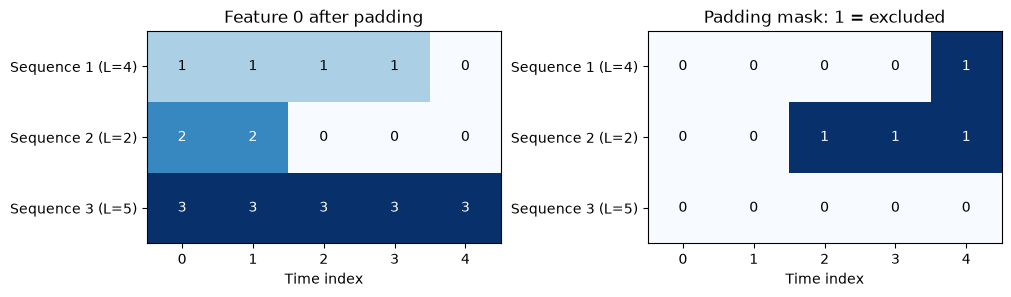

In [6]:
print("padded shape:", tuple(padded.shape))
print("mask shape:", tuple(mask.shape))
print("lengths:", lengths.tolist())
fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for ax, values, title, is_mask in zip(axes, [padded[:, :, 0].numpy(), mask.numpy()],
                                    ["Feature 0 after padding", "Padding mask: 1 = excluded"], [False, True]):
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1 if is_mask else 3)
    for b in range(3):
        for t in range(5):
            ax.text(t, b, str(int(values[b, t])), ha="center", va="center",
                    color="white" if values[b, t] > (0.5 if is_mask else 1.5) else "black")
    ax.set_xticks(range(5))
    ax.set_yticks(range(3), ["Sequence 1 (L=4)", "Sequence 2 (L=2)", "Sequence 3 (L=5)"])
    ax.set_xlabel("Time index")
    ax.set_title(title)
fig.savefig(out / "padding_mask_view.png", dpi=140)
plt.show()
plt.close(fig)

### 1-1. sequences를 읽는 방법
```python
sequences = [torch.ones(4, 3), torch.ones(2, 3) * 2, torch.ones(5, 3) * 3]
```

`sequences`는 Python 리스트이며 리스트 안의 **각 텐서 하나가 독립된 자료 한 개**입니다. 각 텐서는 `[L,F]` 형태이고, L은 실제 시점 수, F는 한 시점의 특성 수입니다.

| 원소 | shape | 한 시점의 값 | 의미 |
| --- | --- | --- | --- |
| `sequences[0]` | `(4,3)` | `[1,1,1]` | 4시점, 시점마다 특성 3개 |
| `sequences[1]` | `(2,3)` | `[2,2,2]` | 2시점, 시점마다 특성 3개 |
| `sequences[2]` | `(5,3)` | `[3,3,3]` | 5시점, 시점마다 특성 3개 |

`torch.ones(4,3)`은 1로 채운 4행 3열 텐서를 만듭니다. `*2`, `*3`은 모든 값에 곱하며 길이나 특성 수는 바꾸지 않습니다. 여기서 길이는 다르지만 F는 모두 3입니다. dtype과 시간축 이외의 크기도 맞춰서 준비합니다.

길이가 달라 그대로 `torch.stack(sequences)`를 할 수 없으므로 Padding으로 길이를 맞춥니다. 반면 `torch.cat(sequences, dim=0)`은 11시점으로 이어 붙여 자료별 배치 축이 생기지 않으므로 이 작업을 대신하지 못합니다.

`lengths`는 실제 길이를 원본 순서로 저장한 `[4,2,5]`입니다. Padding 후의 shape만으로 각 실제 길이를 알 수 없으므로 별도로 보관합니다. 실무에서는 `torch.tensor([seq.size(0) for seq in sequences])`로 구할 수 있습니다.

In [7]:
for i, seq in enumerate(state["sequences"]):
    print(f"sequences[{i}] shape={tuple(seq.shape)}\n{seq}")
measured_lengths = torch.tensor([seq.size(0) for seq in state["sequences"]])
assert torch.equal(measured_lengths, lengths)
print("실제 길이:", measured_lengths.tolist())

sequences[0] shape=(4, 3)
tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])
sequences[1] shape=(2, 3)
tensor([[2., 2., 2.],
        [2., 2., 2.]])
sequences[2] shape=(5, 3)
tensor([[3., 3., 3.],
        [3., 3., 3.],
        [3., 3., 3.],
        [3., 3., 3.],
        [3., 3., 3.]])
실제 길이: [4, 2, 5]


### 1-2. pad_sequence와 batch_first
```python
padded = pad_sequence(sequences, batch_first=True)
```

Padding은 가장 긴 자료의 길이 T=5를 기준으로 빈 시점을 채워 배치 텐서를 만드는 과정입니다. 이 호출은 기본값 `padding_value=0.0`, 오른쪽 Padding을 사용합니다. 자료 1에는 1시점, 자료 2에는 3시점, 자료 3에는 0시점이 추가됩니다. 한 Padding 시점에는 특성 3개가 모두 채워집니다.

| 설정 | 출력 축 순서 | 이번 shape | 시간 합산 축 |
| --- | --- | --- | --- |
| `batch_first=True` | B·T·F | `(3,5,3)` | `dim=1` |
| `batch_first=False` (기본값) | T·B·F | `(5,3,3)` | `dim=0` |

batch_first는 새 배치 축을 어디에 놓는지 정하며 시간 순서나 자료 순서를 바꾸지 않습니다. `True`가 첫 자료만 처리한다는 의미도 아닙니다. 입력 리스트의 각 텐서는 어느 설정이든 `[L,F]`로 동일합니다.

이 예제에서는 `padded[1]`이 두 번째 자료 전체 `[5,3]`이고, `padded[1,0]`은 그 자료의 첫 시점 특성 `[3]`입니다. 반면 TBF 텐서의 `[1]`은 두 번째 **시점**에서 모든 자료의 특성입니다. B와 F가 우연히 모두 3이므로 숫자 shape만 보지 말고 축 의미도 확인해야 합니다.

In [8]:
btf = pad_sequence(state["sequences"], batch_first=True)
tbf = pad_sequence(state["sequences"], batch_first=False)
assert btf.shape == (3, 5, 3)
assert tbf.shape == (5, 3, 3)
assert torch.equal(btf, tbf.permute(1, 0, 2))
print("batch_first=True:", tuple(btf.shape))
print("batch_first=False:", tuple(tbf.shape))
print("BTF에서 두 번째 자료:\n", btf[1])
print("TBF에서 두 번째 자료:\n", tbf[:,1,:])
# TBF를 그대로 계산한다면 마스크도 [T,B]로 만들고 dim=0으로 합산합니다.
mask_tb = torch.arange(tbf.size(0)).unsqueeze(1) >= lengths.unsqueeze(0)
mean_tbf = (tbf * (~mask_tb).unsqueeze(-1)).sum(dim=0) / lengths.unsqueeze(1)
assert torch.allclose(mean_tbf, mean)
print("TBF로 계산한 실제 평균도 동일:", torch.allclose(mean_tbf, mean))

batch_first=True: (3, 5, 3)
batch_first=False: (5, 3, 3)
BTF에서 두 번째 자료:
 tensor([[2., 2., 2.],
        [2., 2., 2.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])
TBF에서 두 번째 자료:
 tensor([[2., 2., 2.],
        [2., 2., 2.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])
TBF로 계산한 실제 평균도 동일: True


### 1-3. padding_value와 padding_side
`padding_value`는 새로 추가하는 값이며, 원래 자료의 값이나 실제 길이를 바꾸지 않습니다. 0 이외의 값으로 채워도 길이 기반 마스크로 제외하면 같은 평균이 나와야 합니다.

`padding_side="right"`는 실제 값 뒤를 채웁니다. 현재 설치된 PyTorch는 `padding_side="left"`도 지원합니다. 왼쪽 Padding에서는 실제 시점이 마지막 L개에 있으므로 현재의 `t >= length` 마스크를 그대로 쓰면 안 됩니다.

- 오른쪽 Padding: `t >= length`인 위치를 제외
- 왼쪽 Padding: `t < T - length`인 위치를 제외

기존 버전에서 `padding_side` 인자가 없다면 아래 예제는 왼쪽에 수동으로 같은 Padding을 붙입니다. 이 실습 본문은 기본 오른쪽 Padding을 사용합니다.

API 인자와 기본값 참고: [PyTorch pad_sequence 공식 문서](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pad_sequence.html).

padding_value=99의 실제 평균:
 tensor([[1., 1., 1.],
        [2., 2., 2.],
        [3., 3., 3.]])
왼쪽 Padding의 특성 0:
 tensor([[0., 1., 1., 1., 1.],
        [0., 0., 0., 2., 2.],
        [3., 3., 3., 3., 3.]])
왼쪽 Padding mask:
 tensor([[ True, False, False, False, False],
        [ True,  True,  True, False, False],
        [False, False, False, False, False]])
왼쪽 Padding의 실제 평균:
 tensor([[1., 1., 1.],
        [2., 2., 2.],
        [3., 3., 3.]])


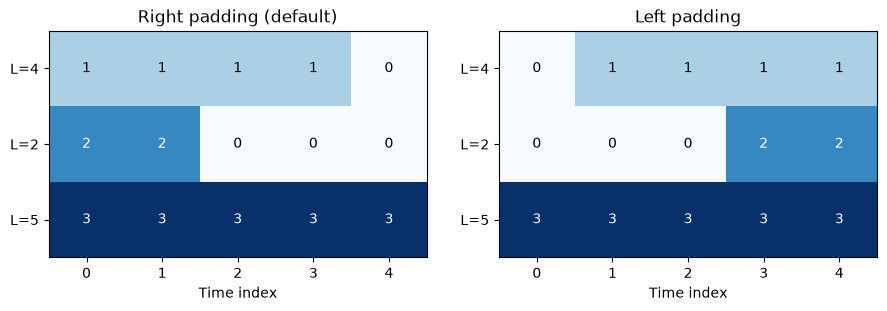

In [9]:
import inspect
# Padding 값을 99로 바꿔도 실제 평균은 변하지 않습니다.
padded_99 = pad_sequence(state["sequences"], batch_first=True, padding_value=99.)
mean_99 = (padded_99 * (~mask).unsqueeze(-1)).sum(dim=1) / lengths.unsqueeze(1)
assert torch.allclose(mean_99, mean)
print("padding_value=99의 실제 평균:\n", mean_99)

if "padding_side" in inspect.signature(pad_sequence).parameters:
    left = pad_sequence(state["sequences"], batch_first=True, padding_side="left")
else:
    left = torch.zeros_like(padded)
    for b, seq in enumerate(state["sequences"]):
        left[b, -seq.size(0):] = seq
left_mask = torch.arange(left.size(1)).unsqueeze(0) < (left.size(1) - lengths).unsqueeze(1)
left_mean = (left * (~left_mask).unsqueeze(-1)).sum(dim=1) / lengths.unsqueeze(1)
assert torch.allclose(left_mean, mean)
print("왼쪽 Padding의 특성 0:\n", left[:,:,0])
print("왼쪽 Padding mask:\n", left_mask)
print("왼쪽 Padding의 실제 평균:\n", left_mean)

fig, axes = plt.subplots(1,2,figsize=(9,3),constrained_layout=True)
for ax, values, title in zip(axes, [padded[:,:,0], left[:,:,0]], ["Right padding (default)", "Left padding"]):
    ax.imshow(values.numpy(), cmap="Blues", vmin=0, vmax=3)
    for b in range(3):
        for t in range(5):
            value = int(values[b,t])
            ax.text(t,b,str(value),ha="center",va="center",color="white" if value>1.5 else "black")
    ax.set_title(title)
    ax.set_xticks(range(5))
    ax.set_yticks(range(3), ["L=4", "L=2", "L=5"])
    ax.set_xlabel("Time index")
fig.savefig(out / "padding_sides_comparison.png", dpi=140)
plt.show()
plt.close(fig)

### 1-4. Padding과 Mask는 역할이 다릅니다
Padding은 shape를 맞추는 저장 표현이고, Mask는 어느 시점을 계산에서 제외할지 알리는 정보입니다. `pad_sequence`는 Mask나 lengths를 자동 반환하지 않습니다. 또한 뒤의 RNN이나 Attention이 Padding을 자동으로 무시하도록 설정하는 함수도 아닙니다.

평균 계산에서는 지금처럼 시점별 Mask와 실제 길이를 사용합니다. 가변 길이 RNN에서는 필요에 따라 `pack_padded_sequence`를 사용하고, Attention에서는 해당 API의 padding mask를 전달합니다. 배치 우선 텐서를 RNN에 넣을 때는 RNN의 `batch_first` 설정도 맞춰야 합니다. 이 설정을 바꿔도 RNN의 hidden state 축 순서까지 모두 바뀌는 것은 아닙니다.

이번 예제는 단일 특성 축 F를 사용하지만 `pad_sequence`는 `[L,*]` 형태도 받을 수 있습니다. 실제로 1차원 `[L]` 자료를 넣으면 F 축 없이 `[B,T]` 또는 `[T,B]`가 됩니다.

## 2. TODO 계산 과정: 실제 시점 마스크 곱하기
현재 코드의 곱셈 마스크 방식으로 계산합니다.

```python
mean = (padded * (~mask).unsqueeze(-1)).sum(dim=1) / lengths.unsqueeze(-1)
```

1. `mask`는 Padding 위치에서 True입니다. `~mask`로 뒤집으면 실제 시점이 True, Padding은 False가 됩니다.
2. `(~mask).unsqueeze(-1)`은 `[B,T] → [B,T,1]`로 바꾸어 모든 특성에 같은 마스크를 적용합니다.
3. `padded * ...`에서 bool 마스크가 곱셈에 사용되면 실제 시점은 1을 곱해 유지하고 Padding은 0을 곱해 제외합니다. 이 예제처럼 값이 유한한 경우에 사용합니다.
4. **곱셈 결과 전체를 괄호로 묶고** `.sum(dim=1)`을 적용해 `[B,T,F] → [B,F]`로 시간축을 합산합니다.
5. `lengths.unsqueeze(-1)`은 `[B] → [B,1]`입니다. 각 자료의 특성별 합을 해당 실제 길이로 나눕니다. lengths는 1차원이므로 이 경우 `unsqueeze(1)`과 같습니다.

### 괄호 위치가 중요한 이유
```python
# 잘못된 식: 마스크만 먼저 합산합니다.
(padded * (~mask).unsqueeze(-1).sum(dim=1)) / lengths.unsqueeze(-1)
```

위 식은 마스크를 `[B,1]`로 줄인 뒤 `[B,T,F]`와 곱하려 하므로 이번 B=3, T=5에서 브로드캐스팅 오류가 납니다. 필요한 연산 순서는 **마스크 곱셈 → 시간축 합산 → 실제 길이로 나누기**입니다.

이전 `masked_fill(mask.unsqueeze(-1), 0)` 방식과 이번 곱셈 방식은 현재 유한한 입력에서 같은 결과를 만듭니다. 다만 Padding에 NaN이나 Inf가 들어 있다면 0을 곱해도 제거되지 않으므로 그 경우에는 `masked_fill()` 등으로 값을 치환해야 합니다.

**실제 평균 = 실제 시점의 합 / 실제 길이**입니다. Tensor의 `mean()`에는 `mask` 인자가 없으며, 단순 `mean(dim=1)`은 최대 길이 5로 나누어 Padding을 포함합니다. 이 실습의 실제 길이는 모두 양수이며 길이 0인 자료는 별도 처리 규칙이 필요합니다.


Padding 포함 평균:
 tensor([[0.8000, 0.8000, 0.8000],
        [0.8000, 0.8000, 0.8000],
        [3.0000, 3.0000, 3.0000]])
실제 시점 평균:
 tensor([[1., 1., 1.],
        [2., 2., 2.],
        [3., 3., 3.]])
 sequence  feature  length  valid_sum  padding_included_mean  masked_mean
        1        0       4        4.0                    0.8          1.0
        1        1       4        4.0                    0.8          1.0
        1        2       4        4.0                    0.8          1.0
        2        0       2        4.0                    0.8          2.0
        2        1       2        4.0                    0.8          2.0
        2        2       2        4.0                    0.8          2.0
        3        0       5       15.0                    3.0          3.0
        3        1       5       15.0                    3.0          3.0
        3        2       5       15.0                    3.0          3.0


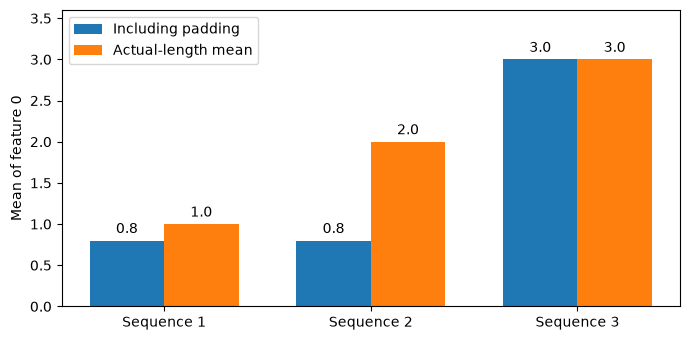

In [10]:
padding_included_mean = padded.mean(dim=1)
valid_sum = (padded * (~mask).unsqueeze(-1)).sum(dim=1)
# 이전 치환 방식과도 같은 결과인지 확인합니다.
assert torch.allclose(valid_sum, padded.masked_fill(mask.unsqueeze(-1), 0).sum(dim=1))
expected = torch.stack([seq.mean(dim=0) for seq in state["sequences"]])
assert torch.allclose(mean, expected)
assert torch.equal((~mask).sum(dim=1), lengths)
print("Padding 포함 평균:\n", padding_included_mean)
print("실제 시점 평균:\n", mean)
rows = []
for b in range(len(lengths)):
    for f in range(padded.size(2)):
        rows.append({"sequence": b+1, "feature": f,
                     "length": lengths[b].item(), "valid_sum": valid_sum[b,f].item(),
                     "padding_included_mean": padding_included_mean[b,f].item(),
                     "masked_mean": mean[b,f].item()})
comparison = pd.DataFrame(rows)
print(comparison.round(3).to_string(index=False))
comparison.to_csv(out / "mask_mean_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.5))
positions = np.arange(3)
ax.bar(positions-.18, padding_included_mean[:,0].numpy(), width=.36, label="Including padding")
ax.bar(positions+.18, mean[:,0].numpy(), width=.36, label="Actual-length mean")
ax.set_xticks(positions, ["Sequence 1", "Sequence 2", "Sequence 3"])
ax.set_ylabel("Mean of feature 0")
ax.set_ylim(0, 3.6)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)
ax.legend()
fig.tight_layout()
fig.savefig(out / "padding_mean_comparison.png", dpi=140)
plt.show()
plt.close(fig)

## 3. 정상 관측값 0은 어떻게 구분하나요?
실제 데이터에 0이 있더라도 평균의 분모에 포함해야 합니다. 예를 들어 실제 시퀀스 `[0, 2]`의 평균은 1입니다. Padding을 붙인 `[0, 2, 0]`에서 길이 2를 사용하면 첫 번째 0은 실제 값이고 마지막 0만 Padding으로 구분할 수 있습니다.

값이 0인 모든 위치를 제외하면 첫 번째 정상 시점까지 빠져서 잘못된 평균 2를 얻게 됩니다.

In [11]:
zero_sequences = [torch.tensor([[0.], [2.]]), torch.tensor([[3.], [3.], [3.]])]
zero_lengths = torch.tensor([2, 3])
zero_padded = pad_sequence(zero_sequences, batch_first=True)
zero_mask = torch.arange(zero_padded.size(1)).unsqueeze(0) >= zero_lengths.unsqueeze(1)
zero_mean = (zero_padded * (~zero_mask).unsqueeze(-1)).sum(dim=1) / zero_lengths.unsqueeze(1)
# 잘못된 방식: 0인 모든 값을 Padding으로 간주해 실제 관측 시점까지 제외합니다.
nonzero_count = (zero_padded != 0).sum(dim=1)
wrong_mean = zero_padded.sum(dim=1) / nonzero_count
print("첫 자료의 padded 값:", zero_padded[0,:,0].tolist())
print("첫 자료의 길이 기반 mask:", zero_mask[0].tolist())
print("올바른 평균:", zero_mean[:,0].tolist())
print("0을 모두 제외한 잘못된 평균:", wrong_mean[:,0].tolist())
assert zero_mean[0,0].item() == 1.0
assert wrong_mean[0,0].item() == 2.0

첫 자료의 padded 값: [0.0, 2.0, 0.0]
첫 자료의 길이 기반 mask: [False, False, True]
올바른 평균: [1.0, 3.0]
0을 모두 제외한 잘못된 평균: [2.0, 3.0]


## 4. 결과 해석 및 추가 실험
| 자료 | 실제 길이 | 특성별 합 | Padding 포함 평균 | 실제 시점 평균 |
| --- | --- | --- | --- | --- |
| 1 | 4 | 4 | 0.8 | 1.0 |
| 2 | 2 | 4 | 0.8 | 2.0 |
| 3 | 5 | 15 | 3.0 | 3.0 |

세 특성의 값이 같아 위 표는 모든 특성에 공통입니다. 길이가 짧은 자료일수록 Padding 포함 평균이 더 작아집니다. 자료 3은 Padding이 없어 두 평균이 같습니다.

### 직접 확인해 볼 내용
- 실제 시퀀스에 0이나 음수를 넣고, 패딩 전 각 시퀀스의 평균과 마스크 평균이 같은지 확인합니다.
- Padding 값을 99로 바꾸어도 실제 시점 마스크를 곱한 평균이 유지되는지 확인합니다.
- `mask.unsqueeze(-1)`의 shape와 `lengths.unsqueeze(1)`의 shape를 출력해 브로드캐스팅 방향을 확인합니다.

### 자주 하는 실수 점검
- True가 Padding이라는 의미를 반대로 사용하지 않았는가?
- 합산 축으로 시점 T인 `dim=1`을 사용했는가?
- 최대 길이 대신 각 자료의 실제 길이로 나눴는가?
- 실제 값 0을 Padding으로 간주하지 않았는가?